# Hybrid-MC: DICOM Data

Hybrid Monte Carlo (MC) SPECT reconstruction uses the SIMIND Monte Carlo program as a backend. Download **SIMIND 8.0** from its [downloads page](https://www.msf.lu.se/en/research/simind-monte-carlo-program/downloads) and install it as its instructions say: put the SIMIND folder first on your `PATH` and set `SMC_DIR` to its `smc_dir` folder. PyTomography is tested with SIMIND 8.0; SIMIND 9.0 is not supported yet. Cite SIMIND as its page asks. Once `simind` runs from a terminal, this tutorial runs.

Hybrid MC SPECT reconstruction replaces conventional forward projection $\bar{y} =H \hat{x}$ with an MC prediction $\bar{y}_{\text{MC}} = \hat{H}_{\text{MC}}\hat{x}$. In practice, the term $\hat{H}_{\text{MC}}\hat{x}$ is estimated all at once via simulation of many individual photons; $\hat{H}_{\text{MC}}$ is given a hat because it is effectively estimated using random variables. Unlike conventional reconstruction $\hat{H}_{\text{MC}}$ estimates the contribution from all photons, so a scatter correction term is not required.

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-NEMA-SymT2")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-NEMA-SymT2")

SPECT/Lu177-NEMA-SymT2: already downloaded


In [2]:
import os
import matplotlib.pyplot as plt
import torch
import pytomography
from pytomography import io
from pytomography.projectors.SPECT import MonteCarloHybridSPECTSystemMatrix
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.algorithms import OSEM
from pytomography.likelihoods import MonteCarloHybridSPECTPoissonLogLikelihood
from pytomography.utils import simind_mc

In [3]:
path = DATA / 'SPECT'

First we'll load the data from the introductory DICOM tutorial. We additioanlly create an attenuation map at 140 keV since this will be required for the MC forward projections.

* The attenuation and PSF transform are used in the analytical back projection

In [4]:
file_NM = os.path.join(path, 'Lu177-NEMA-SymT2', 'projection_data.dcm')
path_CT = os.path.join(path, 'Lu177-NEMA-SymT2', 'CT')
files_CT = [os.path.join(path_CT, f) for f in os.listdir(path_CT)]
projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
photon_energy = proj_meta.energy_windows[0].photon_energy  # the 208 keV window
# 140 keV map is needed for MC forward projector
amap140 = io.attenuation_map(files_CT, object_meta, energy=140.5)
# 208keV is needed for analytical back projection
amap208 = io.attenuation_map(files_CT, object_meta, energy=photon_energy)
att_transform = SPECTAttenuationTransform(amap208)
collimator_name = 'SY-ME'
intrinsic_fwhm = 3.8 # mm
psf_meta = io.SPECT.collimator_psf(
    collimator_name,
    photon_energy,
    intrinsic_fwhm=intrinsic_fwhm
)
psf_transform = SPECTPSFTransform(psf_meta)

The first thing we need in the MC simulation is the energy window parameters from the projection data. This creates a list similar to a scattwin.win file in SIMIND

In [5]:
energy_window_params = simind_mc.get_energy_window_params_dicom(file_NM) 
energy_window_params

['187.19999694824,228.80000305176,0',
 '166.39999389648,187.19999694824,0',
 '228.80000305176,249.60000610352,0',
 '101.69999694824,124.30000305176,0',
 '85.879997253418,101.69999694824,0',
 '124.30000305176,146.89999389648,0']

Now we specify the isotope and detector information that we'll need to feed into our reconstruction
* This needs to be carefully configured for different isotopes

In [6]:
isotope_names = ['lu177'] # isotope we want to simulate
isotope_ratios = [1] # ratio of isotopes (in this case only 1)
collimator_type = 'SY-ME' # collimator type to use
cover_thickness = 1.0 # cover thickness in mm (aluminum assumed)
backscatter_thickness = 66.0 # backscatter thickness in mm (pyrex)
advanced_energy_resolution_model='siemens'
# if the energy resolution model above is not used, then
# the energy resolution needs to be provided at 140keV in
# units of percent.
energy_resolution_140keV = 10 # %
crystal_thickness = 9.525 # thickness of the crystal in mm (NaI)

We also need to choose the number of photons to simulate per projection, as well as the number of parallel CPU jobs to run. I find the 200 million photons per projection works reasonably well for most isotopes. Since I have a powerful computer, I use 90 CPU cores in parallel to run projection (if you have the option, you should select a computer with more CPU power as opposed to GPU power since SIMIND only runs on CPU).
* Set `n_parallel` to the number of cores you can spare: one SIMIND process runs per core, so leave a few for the rest of your computer.

In [7]:
# 200 million events take about 20 minutes on 90 CPU cores, and 45 minutes on 24. Fewer events run faster
# but give a noisier Monte Carlo estimate.
n_events = 200e6
n_parallel = max(1, os.cpu_count() - 4)  # SIMIND processes run at once, one per core; 4 cores left for the rest of the computer

Now we'll build the hybrid system matrix, which performs MC forward projection and analytical back projection. Before it reconstructs, `estimate_memory` says how much RAM and GPU memory it will need, the SIMIND processes included.

In [8]:
system_matrix = MonteCarloHybridSPECTSystemMatrix(
    object_meta,
    proj_meta,
    obj2obj_transforms=[att_transform, psf_transform],
    proj2proj_transforms=[],
    attenuation_map_140keV=amap140,
    energy_window_params=energy_window_params,
    primary_window_idx=0, # based on the 208keV window from energy_window_params
    isotope_names=isotope_names,
    isotope_ratios=isotope_ratios,
    collimator_type=collimator_type,
    crystal_thickness=crystal_thickness,
    cover_thickness=cover_thickness,
    backscatter_thickness=backscatter_thickness,
    advanced_energy_resolution_model=advanced_energy_resolution_model,
    advanced_collimator_modeling=True,
    n_events=n_events,
    n_parallel=n_parallel
)

likelihood = MonteCarloHybridSPECTPoissonLogLikelihood(system_matrix, projections[0])
algorithm = OSEM(likelihood)
print(algorithm.estimate_memory(n_subsets=16))
recon_MC = algorithm(n_iters=1, n_subsets=16)

OSEM (MonteCarloHybridSPECTSystemMatrix): 16 subsets
Peak ~ 6.4 GB RAM, 1.3 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.3 GB GPU (image 0.01 GPU, H_m^T 1 of 16 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, attenuation map at 140 keV 0.01 GPU, projections (the data) 0.01 GPU)
  one subset at a time: 0.02 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy 0.01 GPU, padded object, support and sum of a projection 0.1 GPU, SIMIND maps and the projections of the simulated windows read back (host) 0.02 RAM)
  projector chunks: 1.4 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU, SIMIND processes (20) 1.4 RAM)
  Python, CUDA, allocator: 3.7 GB RAM, 0.9 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU ca

Plot an axial slice of the reconstructed image:

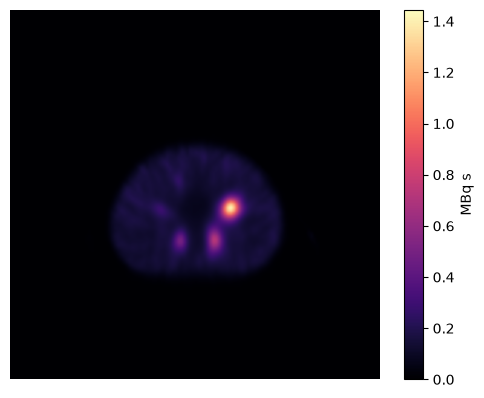

In [9]:
plt.imshow(recon_MC[:,:,60].cpu().T, cmap='magma',interpolation='gaussian')
plt.axis('off')
plt.colorbar(label='MBq s')

It should be noted that the predicted units of the reconstructed image are MBq s (need to divide by the time per projection to get units of MBq). Because of this, point source-based calibration will not work to obtain quantitative units (since the units are already quantitative).

However, there may be discrepancies between the simulated scanner and a real scanner. For this reason, the best way to calibrate is to reconstruct a cylindrical phantom with known activity, segment the cylinder using a 130% boundary (approximately) and then derive a correction factor that puts the MC MBq units to real MBq units (for example, the sensitivity of a real scanner might be 10% lower so a necessary "calibration factor" in this case would be 1.1)

## Save the images

`io.save_dicom` writes the reconstruction as a DICOM nuclear medicine (NM) file, in MBq·s and in its place in the patient (`object_meta.affine`). `reference=file_NM` gives it the patient and study of the projections, so DICOM viewers show it with the scan's CT.

In [10]:
saved = io.save_dicom(recon_MC, OUTPUT / 't_spect_mc2' / 'osem_monte_carlo', object_meta, reference=file_NM,
                      units='MBq.s', series_description='OSEM 1x16, Monte Carlo', overwrite=True)

In [11]:

import json, platform, torch, pytomography
def _peak_ram_gb():
    try:
        import psutil
        m = psutil.Process().memory_info()
        if hasattr(m, "peak_pagefile"):  # Windows: peak committed memory
            return round(m.peak_pagefile / 1e9, 1)
    except ImportError:
        pass
    import resource  # ru_maxrss is in kB on Linux, bytes on macOS
    return round(resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / (1e9 if platform.system() == "Darwin" else 1e6), 1)
_info = dict(pytomography=getattr(pytomography, "__version__", "?"), source=pytomography.__file__,
             torch=torch.__version__, python=platform.python_version(),
             gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
             peak_gpu_gb=round(torch.cuda.max_memory_allocated() / 1e9, 2) if torch.cuda.is_available() else 0.0,
             peak_ram_gb=_peak_ram_gb())
print("__PYTOMOGRAPHY_RUN__" + json.dumps(_info))


__PYTOMOGRAPHY_RUN__{"pytomography": "4.0.0rc1", "source": "C:\\Users\\lukep\\miniforge3\\envs\\pytomo-rc1\\Lib\\site-packages\\pytomography\\__init__.py", "torch": "2.14.1+cu130", "python": "3.12.16", "gpu": "NVIDIA GeForce RTX 5060 Laptop GPU", "peak_gpu_gb": 0.46, "peak_ram_gb": 4.7}
